### Project 2: Diabetes Prediction using Machine Learning with Python (ML)
# Chihat GetHub Linked IN 

في هذا المشروع نحاولوا نديروا بالمودل 
### Linear regression
### SVM (Suport Vector Machine)

In [395]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [396]:
data = pd.read_csv('diabetes.csv') # read the sonar data from the csv file
df = pd.read_csv('diabetes.csv')

In [397]:
data.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


هنا ال
##### outcome
هو 1 اذا مريض 
0 أذا مش مريض

In [398]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [399]:
data.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [400]:
X = data.drop(columns=["Outcome"])
Y = data["Outcome"]

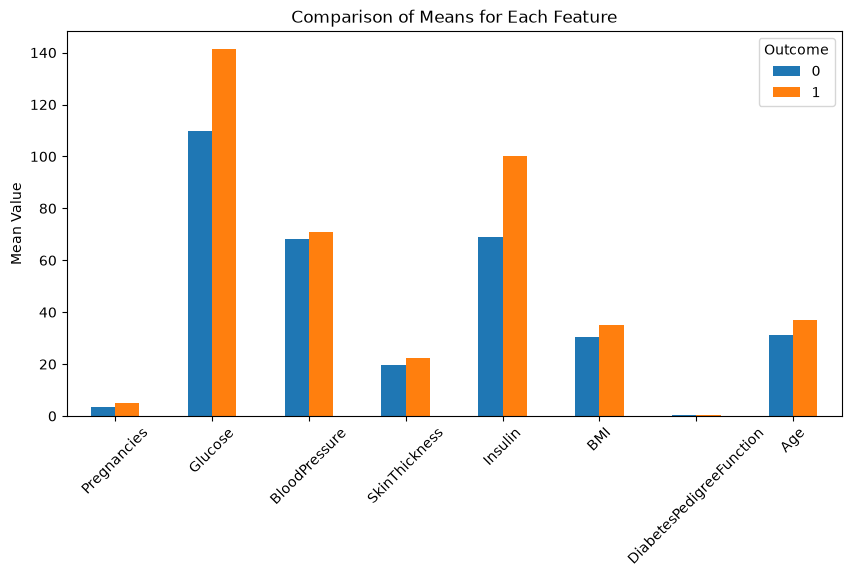

In [401]:
# حساب متوسط كل متغير بناءً على القيمة 0 أو 1 في Outcome ورسمه مباشرة
data.groupby('Outcome').mean().T.plot(kind='bar', figsize=(10, 5))

plt.title('Comparison of Means for Each Feature')
plt.ylabel('Mean Value')
plt.xticks(rotation=45)
plt.show()

الخطوة الاولى نجربو الداتا تاعنا على Linear regression ونشوفو الدقة 

In [402]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()



نقسمو الداتا تاعنا الى بيانات تدريب واختبار

In [403]:
from sklearn.model_selection  import train_test_split

X_train,X_test,Y_train,Y_test = train_test_split(X, Y, test_size=0.2,stratify=Y, random_state=42)

In [404]:
from sklearn.preprocessing import StandardScaler

scalar = StandardScaler()

X_train_scaled = scalar.fit_transform(X_train)

X_test_scaled = scalar.transform(X_test)

In [405]:
print(X.shape)
print(Y.shape)
print(X_train.shape)
print(X_test.shape)
print(Y_train.shape)
print(Y_test.shape)

(768, 8)
(768,)
(614, 8)
(154, 8)
(614,)
(154,)


In [406]:
model.fit(X_train_scaled, Y_train)

X_train_predected = model.predict(X_train_scaled)

from sklearn.metrics import accuracy_score

training_data_accuracy = accuracy_score(Y_train, X_train_predected)

print(f"دقة المودل هي{training_data_accuracy}")

دقة المودل هي0.7915309446254072


In [407]:

X_test_predected = model.predict(X_test_scaled)

testing_data_accuracy = accuracy_score(X_test_predected, Y_test)

print(f"دقة المودل هي{testing_data_accuracy}")

دقة المودل هي0.7142857142857143


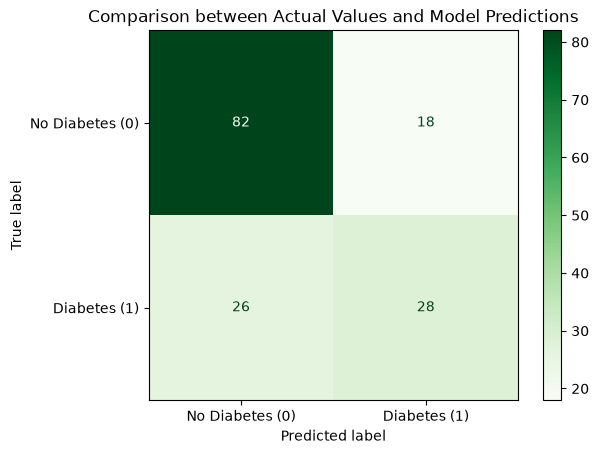

In [408]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 1. حساب مصفوفة الارتباك
cm = confusion_matrix(Y_test, X_test_predected)

# 2. رسم المرفق
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Diabetes (0)', 'Diabetes (1)'])
disp.plot(cmap='Greens')

plt.title('Comparison between Actual Values and Model Predictions')
plt.show()

###    الأن بإستعمال SVM Support vector machine

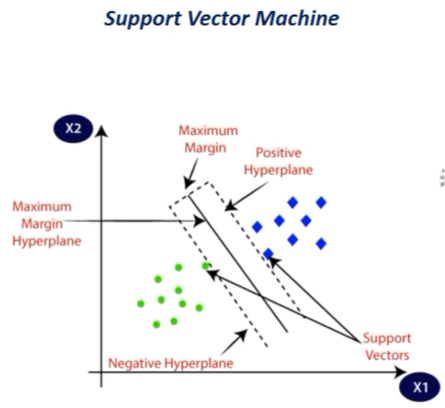

In [409]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [410]:
df.shape

(768, 9)

In [411]:
df["Outcome"].value_counts()

Outcome
0    500
1    268
Name: count, dtype: int64

In [412]:
df.groupby('Outcome').mean()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
Outcome,,,,,,,,
0,3.298000,109.980000,68.184000,19.664000,68.792000,30.304200,0.429734,31.190000
1,4.865672,141.257463,70.824627,22.164179,100.335821,35.142537,0.550500,37.067164


In [413]:
X = df.drop(columns=["Outcome"])
Y = df["Outcome"]

DATA Standardization

In [414]:
scalar = StandardScaler()

X = scalar.fit_transform(X)

In [415]:
X

array([[ 0.63994726,  0.84832379,  0.14964075, ...,  0.20401277,
         0.46849198,  1.4259954 ],
       [-0.84488505, -1.12339636, -0.16054575, ..., -0.68442195,
        -0.36506078, -0.19067191],
       [ 1.23388019,  1.94372388, -0.26394125, ..., -1.10325546,
         0.60439732, -0.10558415],
       ...,
       [ 0.3429808 ,  0.00330087,  0.14964075, ..., -0.73518964,
        -0.68519336, -0.27575966],
       [-0.84488505,  0.1597866 , -0.47073225, ..., -0.24020459,
        -0.37110101,  1.17073215],
       [-0.84488505, -0.8730192 ,  0.04624525, ..., -0.20212881,
        -0.47378505, -0.87137393]], shape=(768, 8))

In [416]:
X_train,X_test,Y_train,Y_test = train_test_split(X, Y, test_size=0.2,stratify=Y, random_state=1)

In [417]:
from sklearn.svm import SVC

model = SVC(kernel='linear')

In [418]:
model.fit(X_train, Y_train)

X_train_predected = model.predict(X_train)

In [419]:

X_test_predected = model.predict(X_test)

In [420]:
model_accuracy_train = accuracy_score(X_train_predected , Y_train)
print(f"الدقة بالنسبة لبيانات التدريب {model_accuracy_train}")
model_accuracy_test = accuracy_score(X_test_predected , Y_test)
print(f"الدقة بالنسبة لبيانات الإختبارب {model_accuracy_test}")

الدقة بالنسبة لبيانات التدريب 0.7833876221498371
الدقة بالنسبة لبيانات الإختبارب 0.7792207792207793


ذرك الإختبار نجربو نختبروه بمرضى وطبيعيين

9,156,86,28,155,34.3,1.189,42,1 نجربو هذا راه DIABETIC

In [421]:
input_data = (9,156,86,28,155,34.3,1.189,42)
input_array = np.asarray(input_data)

input_array_reshap = input_array.reshape(1,-1)
std_data = scalar.transform(input_array_reshap)
k = model.predict(std_data)

if k==0:
    print("NOt DIABETIC !!")
else:
    print("IS DIABETIC !!")

IS DIABETIC !!


c:\Users\Pc\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
